# Pruebas de velocidad 


## Etiquetas de estos clips

- `0000`: Gracias
- `0001`: Buenos dias
- `0003`: Buenas noches

Primero se muestran los videos y sus metadatos de captura (fotogramas, FPS y duracion). Tambien se calcula una **velocidad relativa aproximada** por clase a partir de la duracion completa del clip: una repeticion mas corta tiene un valor mayor respecto a la duracion mediana de las otras repeticiones de esa misma seña. No es una medicion biomecanica ni necesariamente el tiempo exacto del gesto.

Despues se extraen landmarks y se predice. Los videos originales no se modifican. 

In [20]:
import mediapipe as mp

print(f"MediaPipe {mp.__version__}; el notebook selecciona el backend Holistic disponible.")

MediaPipe 0.10.21; el notebook selecciona el backend Holistic disponible.


In [21]:
from pathlib import Path
import hashlib
import importlib
import re
import shutil
import sys
from urllib.request import urlopen

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, Video, display

PROJECT_DIR = Path(r"D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition")
CODE_DIR = PROJECT_DIR.parent
resolved_code_dir = CODE_DIR.resolve()
sys.path = [entry for entry in sys.path if Path(entry or ".").resolve() != resolved_code_dir]
sys.path.insert(0, str(resolved_code_dir))
importlib.invalidate_caches()

import landmark_recognition
expected_package_file = (PROJECT_DIR / "__init__.py").resolve()
loaded_package_file = Path(landmark_recognition.__file__).resolve()
if loaded_package_file != expected_package_file:
    raise ImportError(
        f"Se cargo landmark_recognition desde {loaded_package_file}, pero se esperaba {expected_package_file}. "
        "Reinicia el kernel y vuelve a ejecutar las celdas desde el inicio."
    )

from landmark_recognition.class_labels import display_class_name
from landmark_recognition.data import HAND_LANDMARKS, LANDMARK_COUNT, POSE_LANDMARKS, resample_sequence
from landmark_recognition.inference import load_checkpoint_model, prepare_checkpoint_features

EXPERIMENT_DIR = PROJECT_DIR / "data" / "experimentos_propios"
NEW_VIDEO_DIR = PROJECT_DIR / "Videos diferente velocidad"
LEGACY_VIDEO_DIR = EXPERIMENT_DIR / "videos"
VIDEO_DIR = NEW_VIDEO_DIR if NEW_VIDEO_DIR.is_dir() else LEGACY_VIDEO_DIR
LANDMARK_DIR = EXPERIMENT_DIR / "landmarks"
RESULTS_DIR = EXPERIMENT_DIR / "resultados"
MODEL_DIR = EXPERIMENT_DIR / "modelos"
for folder in (VIDEO_DIR, LANDMARK_DIR, RESULTS_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "transformer_intersection.pth"
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"No se encontro el checkpoint: {CHECKPOINT_PATH}")
model, checkpoint = load_checkpoint_model(CHECKPOINT_PATH, torch.device("cpu"))
class_codes = [str(code) for code in checkpoint["class_names"]]
class_index = {code: index for index, code in enumerate(class_codes)}
frame_count = int(checkpoint["frame_count"])

MAX_EXTRACTION_FRAMES = 96
VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
FILENAME_PATTERN = re.compile(r"^(?P<participant>\d+)_(?P<repetition>\d+)_(?P<sign>\d{4})$")
USE_SOLUTIONS = hasattr(mp, "solutions") and hasattr(mp.solutions, "holistic")
MODEL_ASSET_URL = "https://storage.googleapis.com/mediapipe-models/holistic_landmarker/holistic_landmarker/float16/1/holistic_landmarker.task"
shared_model_path = PROJECT_DIR / "data" / "experimentos_velocidad" / "modelos" / "holistic_landmarker.task"
MODEL_ASSET_PATH = shared_model_path if shared_model_path.is_file() else MODEL_DIR / "holistic_landmarker.task"
if USE_SOLUTIONS:
    EXTRACTOR_BACKEND = "MediaPipe Solutions Holistic (compatible con entrenamiento)"
elif False and hasattr(mp, "tasks") and hasattr(mp.tasks.vision, "HolisticLandmarker"):
    EXTRACTOR_BACKEND = "MediaPipe Tasks Holistic (backend disponible; distinto al de entrenamiento)"
    if not MODEL_ASSET_PATH.is_file():
        temporary_path = MODEL_ASSET_PATH.with_suffix(".task.download")
        try:
            with urlopen(MODEL_ASSET_URL, timeout=60) as response, temporary_path.open("wb") as output:
                shutil.copyfileobj(response, output)
            if temporary_path.stat().st_size < 1_000_000:
                raise RuntimeError(f"El archivo descargado parece incompleto: {temporary_path}")
            temporary_path.replace(MODEL_ASSET_PATH)
        except (OSError, RuntimeError):
            temporary_path.unlink(missing_ok=True)
            raise
else:
    raise RuntimeError(f"MediaPipe {getattr(mp, '__version__', 'desconocida')} no ofrece Solutions Holistic; instala mediapipe==0.10.21.")

print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Modelo: {checkpoint['architecture']} | frames por inferencia: {frame_count} | features por frame: {checkpoint['input_size']}")
print(f"Videos: {VIDEO_DIR}")
print(f"Fuente de videos nuevos: {'si' if VIDEO_DIR == NEW_VIDEO_DIR else 'no (se usa la carpeta historica)'}")
print(f"Extractor: {EXTRACTOR_BACKEND}")


Checkpoint: D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\checkpoints\transformer_intersection.pth
Modelo: transformer | frames por inferencia: 64 | features por frame: 450
Videos: D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\Videos diferente velocidad
Fuente de videos nuevos: si
Extractor: MediaPipe Solutions Holistic (compatible con entrenamiento)


D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\models.py:62: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=layers)


## 1. Ver  videos y la velocidad de captura

Cada reproductor va acompañado por participante, repeticion, seña, cantidad de fotogramas, FPS, duracion y ritmo relativo estimado. El valor FPS es la frecuencia de fotogramas del archivo; el ritmo relativo compara duraciones entre repeticiones de la misma clase. 

In [22]:
video_paths = sorted(path for path in VIDEO_DIR.iterdir() if path.is_file() and path.suffix.lower() in VIDEO_EXTENSIONS)
if not video_paths:
    raise FileNotFoundError(f"No hay videos en {VIDEO_DIR}")

catalog_rows = []
for video_path in video_paths:
    match = FILENAME_PATTERN.fullmatch(video_path.stem)
    if match is None:
        raise ValueError(f"Nombre no valido; se esperaba participante_repeticion_sena: {video_path.name}")
    participant = match.group("participant")
    repetition = match.group("repetition")
    sign_code = match.group("sign")
    if sign_code not in class_index:
        raise ValueError(f"La etiqueta {sign_code} de {video_path.name} no existe en el checkpoint.")
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise RuntimeError(f"OpenCV no pudo abrir el video: {video_path}")
    frame_total = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(capture.get(cv2.CAP_PROP_FPS))
    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    capture.release()
    if frame_total < 1 or not np.isfinite(fps) or fps <= 0:
        raise RuntimeError(f"Metadatos invalidos en {video_path.name}: frames={frame_total}, FPS={fps}")
    duration = frame_total / fps
    catalog_rows.append({
        "archivo": video_path.name,
        "participante": participant,
        "repeticion": repetition,
        "codigo_sena": sign_code,
        "sena": display_class_name(sign_code),
        "fotogramas": frame_total,
        "fps_captura": fps,
        "duracion_s": duration,
        "resolucion": f"{width}x{height}",
        "ruta": video_path,
    })

catalog_df = pd.DataFrame(catalog_rows)
median_duration = catalog_df.groupby("codigo_sena")["duracion_s"].transform("median")
catalog_df["ritmo_relativo_aprox"] = median_duration / catalog_df["duracion_s"]
catalog_df["lectura_ritmo"] = np.where(catalog_df["ritmo_relativo_aprox"] > 1, "mas rapida que mediana", np.where(catalog_df["ritmo_relativo_aprox"] < 1, "mas lenta que mediana", "cerca de mediana"))

for sign_code, group in catalog_df.groupby("codigo_sena", sort=True):
    display(HTML(f"<h3>{sign_code} - {display_class_name(sign_code)}</h3>"))
    for _, row in group.sort_values("repeticion").iterrows():
        display(HTML(
            f"<b>{row['archivo']}</b> | participante {row['participante']} | repeticion {row['repeticion']}<br>"
            f"{row['fotogramas']} fotogramas | {row['fps_captura']:.2f} FPS | {row['duracion_s']:.2f} s | "
            f"ritmo relativo aprox. {row['ritmo_relativo_aprox']:.2f}x ({row['lectura_ritmo']}) | {row['resolucion']}"
        ))
        display(Video(filename=str(row["ruta"]), embed=True, width=480))

print(f"Clips mostrados: {len(catalog_df)}. A continuacion se ejecuta la prediccion en una celda separada.")
display(catalog_df.drop(columns=["ruta"]).sort_values(["codigo_sena", "repeticion"]).reset_index(drop=True).round({"fps_captura": 2, "duracion_s": 3, "ritmo_relativo_aprox": 2}))


Clips mostrados: 9. A continuacion se ejecuta la prediccion en una celda separada.


,archivo,participante,repeticion,codigo_sena,sena,fotogramas,fps_captura,duracion_s,resolucion,ritmo_relativo_aprox,lectura_ritmo
0,0010_0001_0000.mp4,0010,0001,0000,GRACIAS,165,58.62,2.815,480x864,0.88,mas lenta que mediana
1,0010_0002_0000.mp4,0010,0002,0000,GRACIAS,145,58.62,2.474,480x864,1.00,cerca de mediana
2,0010_0003_0000.mp4,0010,0003,0000,GRACIAS,108,58.61,1.843,480x864,1.34,mas rapida que mediana
3,0010_0001_0001.mp4,0010,0001,0001,BUENOS DÍAS,182,58.62,3.105,480x864,1.00,cerca de mediana
4,0010_0002_0001.mp4,0010,0002,0001,BUENOS DÍAS,139,58.62,2.371,480x864,1.31,mas rapida que mediana
5,0010_0003_0001.mp4,0010,0003,0001,BUENOS DÍAS,248,58.38,4.248,480x864,0.73,mas lenta que mediana
6,0010_0001_0003.mp4,0010,0001,0003,BUENAS NOCHES,205,58.62,3.497,480x864,1.00,cerca de mediana
7,0010_0002_0003.mp4,0010,0002,0003,BUENAS NOCHES,172,58.62,2.934,480x864,1.19,mas rapida que mediana
8,0010_0003_0003.mp4,0010,0003,0003,BUENAS NOCHES,225,58.62,3.838,480x864,0.91,mas lenta que mediana


## 2. Extraer landmarks e inferir 



In [23]:
def result_to_landmarks(result) -> np.ndarray:
    sequence = np.zeros((LANDMARK_COUNT, 3), dtype=np.float32)
    for offset, detected, expected in (
        (0, result.pose_landmarks, POSE_LANDMARKS),
        (POSE_LANDMARKS, result.left_hand_landmarks, HAND_LANDMARKS),
        (POSE_LANDMARKS + HAND_LANDMARKS, result.right_hand_landmarks, HAND_LANDMARKS),
    ):
        points = detected.landmark if hasattr(detected, "landmark") else detected
        if points is None:
            continue
        for index, point in enumerate(points[:expected]):
            sequence[offset + index] = (point.x, point.y, point.z)
    return sequence


def extract_landmarks(video_path: Path, max_frames: int = MAX_EXTRACTION_FRAMES) -> tuple[np.ndarray, np.ndarray]:
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise RuntimeError(f"OpenCV no pudo abrir {video_path}")
    frame_total = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = float(capture.get(cv2.CAP_PROP_FPS))
    if frame_total < 1 or not np.isfinite(fps) or fps <= 0:
        capture.release()
        raise RuntimeError(f"Frames/FPS invalidos para {video_path.name}")
    source_indices = np.unique(np.linspace(0, frame_total - 1, min(frame_total, max_frames)).round().astype(np.int64))
    landmarks = []
    try:
        if USE_SOLUTIONS:
            detector_context = mp.solutions.holistic.Holistic(
                static_image_mode=False,
                model_complexity=1,
                enable_segmentation=False,
                refine_face_landmarks=False,
            )
        else:
            options = mp.tasks.vision.HolisticLandmarkerOptions(
                base_options=mp.tasks.BaseOptions(model_asset_path=str(MODEL_ASSET_PATH)),
                running_mode=mp.tasks.vision.RunningMode.VIDEO,
                min_face_detection_confidence=0.5,
                min_pose_detection_confidence=0.5,
                min_hand_landmarks_confidence=0.5,
                output_face_blendshapes=False,
                output_pose_segmentation_masks=False,
            )
            detector_context = mp.tasks.vision.HolisticLandmarker.create_from_options(options)
        with detector_context as landmarker:
            previous_timestamp = -1
            for source_index in source_indices:
                capture.set(cv2.CAP_PROP_POS_FRAMES, int(source_index))
                ok, frame = capture.read()
                if not ok:
                    raise RuntimeError(f"No se pudo leer fotograma {source_index} de {video_path.name}")
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                timestamp_ms = max(int(round(int(source_index) * 1000 / fps)), previous_timestamp + 1)
                if USE_SOLUTIONS:
                    result = landmarker.process(rgb)
                else:
                    image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
                    result = landmarker.detect_for_video(image, timestamp_ms)
                landmarks.append(result_to_landmarks(result))
                previous_timestamp = timestamp_ms
    finally:
        capture.release()
    if not landmarks:
        raise RuntimeError(f"No se extrajeron landmarks: {video_path.name}")
    return np.stack(landmarks).astype(np.float32, copy=False), source_indices


results = []
all_probabilities = []
code_to_index = {str(code): index for index, code in enumerate(class_codes)}
print("class_codes primeros 20:", class_codes[:20])
print("len class_codes:", len(class_codes))
print("codigo 0000 ->", class_index.get("0000"))
print("codigo 0001 ->", class_index.get("0001"))
print("codigo 0003 ->", class_index.get("0003"))
print("codigo 0036 ->", class_index.get("0036"))
for row in catalog_df.to_dict(orient="records"):
    video_path = row["ruta"]
    raw_landmarks, source_indices = extract_landmarks(video_path)
    raw_path = LANDMARK_DIR / f"{video_path.stem}.npz"
    np.savez_compressed(
        raw_path,
        landmarks=raw_landmarks,
        source_frame_indices=source_indices,
        fps=np.asarray(row["fps_captura"], dtype=np.float32),
        source_frame_count=np.asarray(row["fotogramas"], dtype=np.int64),
        source_video=np.asarray(video_path.name),
    )

    sampled = resample_sequence(
        raw_landmarks.reshape(len(raw_landmarks), LANDMARK_COUNT * 3),
        frame_count
    ).reshape(frame_count, LANDMARK_COUNT, 3)

    features = prepare_checkpoint_features(sampled, checkpoint)
    with torch.inference_mode():
        logits = model(torch.from_numpy(features[None]))
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()
    all_probabilities.append(probabilities)

    top_indices = np.argsort(probabilities)[::-1][:3]
    predicted_index = int(top_indices[0])
    predicted_code = class_codes[predicted_index]

    actual_code = str(row["codigo_sena"])
    if actual_code not in code_to_index:
        raise ValueError(f"El código {actual_code} no existe en class_codes: {class_codes[:10]} ...")

    actual_index = code_to_index[actual_code]
    detected = np.any(np.abs(raw_landmarks) > 1e-8, axis=-1)

    results.append({
        "archivo": video_path.name,
        "participante": row["participante"],
        "repeticion": row["repeticion"],
        "codigo_real": actual_code,
        "sena_real": row["sena"],
        "prediccion": predicted_code,
        "nombre_prediccion": display_class_name(predicted_code),
        "acierto": predicted_code == actual_code,
        "confianza_top1": float(probabilities[predicted_index]),
        "probabilidad_real": float(probabilities[actual_index]),
        "fps_captura": row["fps_captura"],
        "duracion_s": row["duracion_s"],
        "ritmo_relativo_aprox": row["ritmo_relativo_aprox"],
        "fotogramas_originales": row["fotogramas"],
        "fotogramas_landmarks": len(raw_landmarks),
        "cobertura_pose": float(detected[:, :POSE_LANDMARKS].mean()),
        "cobertura_mano_izquierda": float(detected[:, POSE_LANDMARKS:POSE_LANDMARKS + HAND_LANDMARKS].mean()),
        "cobertura_mano_derecha": float(detected[:, POSE_LANDMARKS + HAND_LANDMARKS:].mean()),
        "landmarks_npz": str(raw_path),
        "top3": " | ".join(
            f"{class_codes[i]} {display_class_name(class_codes[i])}: {probabilities[i]:.1%}"
            for i in top_indices
        ),
    })

    print(
        f"{video_path.name}: real={actual_code} {row['sena']} -> "
        f"prediccion={predicted_code} {display_class_name(predicted_code)} "
        f"({probabilities[predicted_index]:.1%})"
    )
predictions_df = pd.DataFrame(results)
results_path = RESULTS_DIR / "predicciones_videos_propios.csv"
predictions_df.to_csv(results_path, index=False, encoding="utf-8-sig")
print(f"\nResultados guardados en: {results_path}")
display(predictions_df[["archivo", "codigo_real", "prediccion", "acierto", "confianza_top1", "probabilidad_real", "fps_captura", "fotogramas_originales", "fotogramas_landmarks", "ritmo_relativo_aprox", "cobertura_pose", "cobertura_mano_izquierda", "cobertura_mano_derecha", "top3"]].round(3))


class_codes primeros 20: ['0000', '0001', '0002', '0003', '0024', '0025', '0027', '0030', '0032', '0033', '0034', '0035', '0036', '0050', '0051', '0052', '0053']
len class_codes: 17
codigo 0000 -> 0
codigo 0001 -> 1
codigo 0003 -> 3
codigo 0036 -> 12
0010_0001_0000.mp4: real=0000 GRACIAS -> prediccion=0036 PERMISO (36.6%)
0010_0001_0001.mp4: real=0001 BUENOS DÍAS -> prediccion=0036 PERMISO (35.1%)
0010_0001_0003.mp4: real=0003 BUENAS NOCHES -> prediccion=0036 PERMISO (89.7%)
0010_0002_0000.mp4: real=0000 GRACIAS -> prediccion=0025 MAL (19.4%)
0010_0002_0001.mp4: real=0001 BUENOS DÍAS -> prediccion=0036 PERMISO (35.2%)
0010_0002_0003.mp4: real=0003 BUENAS NOCHES -> prediccion=0036 PERMISO (59.6%)
0010_0003_0000.mp4: real=0000 GRACIAS -> prediccion=0036 PERMISO (20.7%)
0010_0003_0001.mp4: real=0001 BUENOS DÍAS -> prediccion=0036 PERMISO (29.4%)
0010_0003_0003.mp4: real=0003 BUENAS NOCHES -> prediccion=0036 PERMISO (84.1%)

Resultados guardados en: D:\Noveno\Fase 2\Reconocimiento-del-Leng

,archivo,codigo_real,prediccion,acierto,confianza_top1,probabilidad_real,fps_captura,fotogramas_originales,fotogramas_landmarks,ritmo_relativo_aprox,cobertura_pose,cobertura_mano_izquierda,cobertura_mano_derecha,top3
0,0010_0001_0000.mp4,0000,0036,False,0.366,0.141,58.616,165,96,0.879,1.0,0.906,0.979,0036 PERMISO: 36.6% | 0000 GRACIAS: 14.1% | 00...
1,0010_0001_0001.mp4,0001,0036,False,0.351,0.204,58.615,182,96,1.000,1.0,0.917,0.969,0036 PERMISO: 35.1% | 0001 BUENOS DÍAS: 20.4% ...
2,0010_0001_0003.mp4,0003,0036,False,0.897,0.022,58.617,205,96,1.000,1.0,0.906,0.979,0036 PERMISO: 89.7% | 0003 BUENAS NOCHES: 2.2%...
3,0010_0002_0000.mp4,0000,0025,False,0.194,0.126,58.619,145,96,1.000,1.0,0.990,0.969,0025 MAL: 19.4% | 0036 PERMISO: 16.9% | 0050 C...
4,0010_0002_0001.mp4,0001,0036,False,0.352,0.202,58.618,139,96,1.309,1.0,0.979,0.938,0036 PERMISO: 35.2% | 0001 BUENOS DÍAS: 20.2% ...
5,0010_0002_0003.mp4,0003,0036,False,0.596,0.071,58.616,172,96,1.192,1.0,0.656,0.948,0036 PERMISO: 59.6% | 0003 BUENAS NOCHES: 7.1%...
6,0010_0003_0000.mp4,0000,0036,False,0.207,0.045,58.614,108,96,1.342,1.0,0.823,0.885,0036 PERMISO: 20.7% | 0025 MAL: 18.5% | 0002 B...
7,0010_0003_0001.mp4,0001,0036,False,0.294,0.217,58.382,248,96,0.731,1.0,0.969,0.990,0036 PERMISO: 29.4% | 0001 BUENOS DÍAS: 21.7% ...
8,0010_0003_0003.mp4,0003,0036,False,0.841,0.042,58.618,225,96,0.911,1.0,0.927,0.958,0036 PERMISO: 84.1% | 0003 BUENAS NOCHES: 4.2%...


Video: 0010_0001_0000.mp4
Forma raw_landmarks: (96, 75, 3)
Min abs: 0.000000
Max abs: 1.476426
Cobertura total: 0.968
Pose coverage: 1.000
Mano izquierda coverage: 0.906
Mano derecha coverage: 0.979


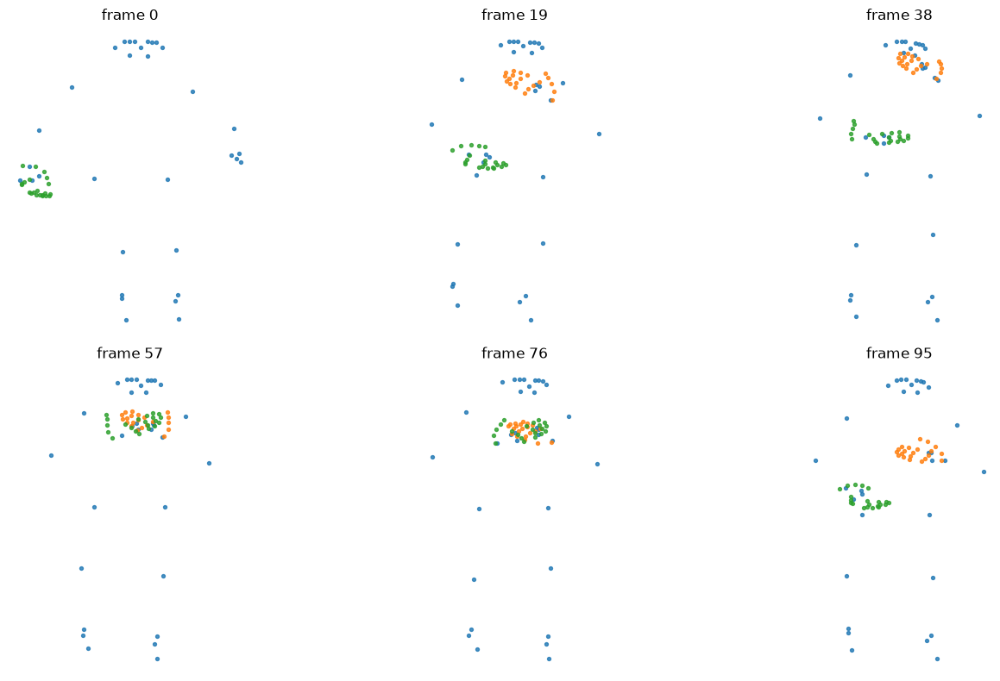


Diagnóstico para: 0010_0001_0000.mp4
Extractor: MediaPipe Solutions Holistic (compatible con entrenamiento)
Frames del video: 165; FPS: 58.62; duración: 2.81s
Formas raw/remuestreada/normalizada/features: (96, 75, 3) / (64, 75, 3) / (64, 75, 3) / (64, 450)
Cobertura pose/mano izq./mano der.: 1.000 / 0.906 / 0.979
Rango normalizado: [-3.055, 3.533]; rango features finales: [-5.490, 4.704]
Checkpoint: 64 frames, 450 features/frame, wrist_relative_hands=True, include_velocity=True
   12 | 0036 PERMISO -> 36.57%
    0 | 0000 GRACIAS -> 14.13%
    5 | 0025 MAL -> 9.78%
    2 | 0002 BUENAS TARDES -> 6.14%
   13 | 0050 CÓMO ESTÁ (COURTESY) -> 5.94%


In [25]:
def inspect_landmarks_for_video(video_path, max_frames=6):
    raw_landmarks, source_indices = extract_landmarks(video_path)
    detected = np.any(np.abs(raw_landmarks) > 1e-8, axis=-1)

    print(f"Video: {video_path.name}")
    print(f"Forma raw_landmarks: {raw_landmarks.shape}")
    print(f"Min abs: {np.abs(raw_landmarks).min():.6f}")
    print(f"Max abs: {np.abs(raw_landmarks).max():.6f}")
    print(f"Cobertura total: {detected.mean():.3f}")
    print(f"Pose coverage: {detected[:, :POSE_LANDMARKS].mean():.3f}")
    print(f"Mano izquierda coverage: {detected[:, POSE_LANDMARKS:POSE_LANDMARKS + HAND_LANDMARKS].mean():.3f}")
    print(f"Mano derecha coverage: {detected[:, POSE_LANDMARKS + HAND_LANDMARKS:].mean():.3f}")

    frame_ids = np.linspace(0, len(raw_landmarks) - 1, min(max_frames, len(raw_landmarks))).astype(int)

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()

    for ax, frame_id in zip(axes, frame_ids):
        points = raw_landmarks[frame_id]
        pose = points[:POSE_LANDMARKS, :2]
        left = points[POSE_LANDMARKS:POSE_LANDMARKS + HAND_LANDMARKS, :2]
        right = points[POSE_LANDMARKS + HAND_LANDMARKS:, :2]

        valid_pose = np.abs(pose).sum(axis=1) > 1e-8
        valid_left = np.abs(left).sum(axis=1) > 1e-8
        valid_right = np.abs(right).sum(axis=1) > 1e-8

        if valid_pose.any():
            ax.scatter(pose[valid_pose, 0], pose[valid_pose, 1], s=8, c="tab:blue", alpha=0.8)
        if valid_left.any():
            ax.scatter(left[valid_left, 0], left[valid_left, 1], s=8, c="tab:orange", alpha=0.8)
        if valid_right.any():
            ax.scatter(right[valid_right, 0], right[valid_right, 1], s=8, c="tab:green", alpha=0.8)

        ax.set_title(f"frame {frame_id}")
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    return raw_landmarks


def diagnose_one_video(video_path):
    from landmark_recognition.data import normalize_landmark_sequence

    video_path = Path(video_path)
    matching_rows = catalog_df.loc[
        catalog_df["ruta"].map(lambda path: Path(path).resolve() == video_path.resolve())
    ]
    if matching_rows.empty:
        raise ValueError(f"El video no está en catalog_df: {video_path}")
    video_info = matching_rows.iloc[0]
    raw_landmarks, source_indices = extract_landmarks(video_path)

    sampled = resample_sequence(
        raw_landmarks.reshape(len(raw_landmarks), LANDMARK_COUNT * 3),
        frame_count
    ).reshape(frame_count, LANDMARK_COUNT, 3)
    normalized = normalize_landmark_sequence(
        sampled,
        wrist_relative_hands=bool(checkpoint.get("wrist_relative_hands", False)),
    )
    features = prepare_checkpoint_features(sampled, checkpoint)
    with torch.inference_mode():
        logits = model(torch.from_numpy(features[None]))
    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()
    top5 = np.argsort(probabilities)[::-1][:5]
    detected = np.any(np.abs(raw_landmarks) > 1e-8, axis=-1)

    print(f"\nDiagnóstico para: {video_path.name}")
    print(f"Extractor: {EXTRACTOR_BACKEND}")
    print(f"Frames del video: {int(video_info['fotogramas'])}; FPS: {video_info['fps_captura']:.2f}; duración: {video_info['duracion_s']:.2f}s")
    print(f"Formas raw/remuestreada/normalizada/features: {raw_landmarks.shape} / {sampled.shape} / {normalized.shape} / {features.shape}")
    print(f"Cobertura pose/mano izq./mano der.: {detected[:, :POSE_LANDMARKS].mean():.3f} / {detected[:, POSE_LANDMARKS:POSE_LANDMARKS + HAND_LANDMARKS].mean():.3f} / {detected[:, POSE_LANDMARKS + HAND_LANDMARKS:].mean():.3f}")
    print(f"Rango normalizado: [{normalized.min():.3f}, {normalized.max():.3f}]; rango features finales: [{features.min():.3f}, {features.max():.3f}]")
    print(f"Checkpoint: {checkpoint['frame_count']} frames, {checkpoint['input_size']} features/frame, wrist_relative_hands={checkpoint.get('wrist_relative_hands', False)}, include_velocity={checkpoint.get('include_velocity', False)}")
    for idx in top5:
        code = class_codes[int(idx)]
        print(f"  {idx:>3} | {code} {display_class_name(code)} -> {probabilities[idx]:.2%}")


# Ejecuta diagnóstico sobre el primer video propio
video_demo = catalog_df["ruta"].iloc[0]
inspect_landmarks_for_video(video_demo)
_ = diagnose_one_video(video_demo)

## Interpretación

- Azul: pose.
- Naranja: mano izquierda.
- Verde: mano derecha.
- Una predicción externa no se considera verdadera ni falsa sin segmentar previamente las señas dentro del video.
- Los videos externos sirven como evidencia independiente del conjunto propio y del firmante de referencia.

## Comparación firmante 0025 y videos propios

Reutiliza los landmarks guardados y extrae solo los que hagan falta. El análisis se divide en orientación/visualización de landmarks y velocidad.

In [26]:
importlib.invalidate_caches()
if not (CODE_DIR / "landmark_recognition" / "subject_comparison.py").is_file():
    raise FileNotFoundError(CODE_DIR / "landmark_recognition" / "subject_comparison.py")

from landmark_recognition.subject_comparison import (
    load_subject_comparison,
    plot_angle_diagnostics,
    plot_parallel_landmark_examples,
    plot_speed_confusions,
    plot_speed_summary,
    summarize_speed_predictions,
)

comparison_catalog, comparison_predictions, comparison_output_dir = load_subject_comparison(globals())
display(
    comparison_catalog.sort_values(["grupo", "codigo_real", "repeticion"])[
        ["grupo_nombre", "participante", "codigo_real", "sena", "archivo", "ancho_px", "alto_px", "fps", "duracion_s"]
    ].round(3)
)

Comparación lista: 9 videos de firmante 0025 y 9 videos propios. Resultados: D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\data\experimentos_propios\comparacion_firmante_0025_vs_propio


,grupo_nombre,participante,codigo_real,sena,archivo,ancho_px,alto_px,fps,duracion_s
0,Firmante 0025 (test),0025,0000,GRACIAS,0.avi,640,480,30.000,3.567
1,Firmante 0025 (test),0025,0000,GRACIAS,1.avi,640,480,30.000,3.833
2,Firmante 0025 (test),0025,0000,GRACIAS,2.avi,640,480,30.000,1.467
3,Firmante 0025 (test),0025,0001,BUENOS DÍAS,0.avi,640,480,30.000,2.267
4,Firmante 0025 (test),0025,0001,BUENOS DÍAS,1.avi,640,480,30.000,2.200
5,Firmante 0025 (test),0025,0001,BUENOS DÍAS,2.avi,640,480,30.000,1.833
6,Firmante 0025 (test),0025,0003,BUENAS NOCHES,0.avi,640,480,30.000,2.567
7,Firmante 0025 (test),0025,0003,BUENAS NOCHES,1.avi,640,480,30.000,1.967
8,Firmante 0025 (test),0025,0003,BUENAS NOCHES,2.avi,640,480,30.000,2.067
9,Videos propios,0010,0000,GRACIAS,0010_0001_0000.mp4,480,864,58.616,2.815


### 1. Orientación y landmarks: de frente y posible oblicuidad

La gráfica usa la diferencia de profundidad de hombros/caderas como **proxy**, no como una medición calibrada del ángulo de cámara. La relación hombros/torso y la inclinación ayudan a detectar cambios de encuadre. Las láminas eligen, para cada seña y grupo, los extremos bajo/alto del proxy y superponen landmarks en tres momentos del gesto. 

,grupo_nombre,codigo_real,sena,archivo,proxy_oblicuidad_mediana,proxy_oblicuidad_p75,ancho_hombros_altura_torso,inclinacion_hombros_deg,cobertura_pose,cobertura_mano_izquierda,cobertura_mano_derecha
1,Firmante 0025 (test),0000,GRACIAS,1.avi,0.176,0.216,0.692,1.169,1.0,0.604,0.177
2,Firmante 0025 (test),0000,GRACIAS,2.avi,0.211,0.332,0.705,1.530,1.0,0.386,0.250
0,Firmante 0025 (test),0000,GRACIAS,0.avi,0.237,0.276,0.674,1.004,1.0,0.250,0.604
5,Firmante 0025 (test),0001,BUENOS DÍAS,2.avi,0.193,0.253,0.722,0.690,1.0,0.418,0.673
4,Firmante 0025 (test),0001,BUENOS DÍAS,1.avi,0.220,0.302,0.679,0.772,1.0,0.621,0.485
3,Firmante 0025 (test),0001,BUENOS DÍAS,0.avi,0.401,0.462,0.681,0.894,1.0,0.441,0.647
8,Firmante 0025 (test),0003,BUENAS NOCHES,2.avi,0.197,0.240,0.704,1.070,1.0,0.468,0.645
6,Firmante 0025 (test),0003,BUENAS NOCHES,0.avi,0.202,0.262,0.706,0.511,1.0,0.519,0.390
7,Firmante 0025 (test),0003,BUENAS NOCHES,1.avi,0.204,0.266,0.699,0.399,1.0,0.678,0.390
12,Videos propios,0000,GRACIAS,0010_0002_0000.mp4,0.218,0.361,0.649,5.011,1.0,0.990,0.969


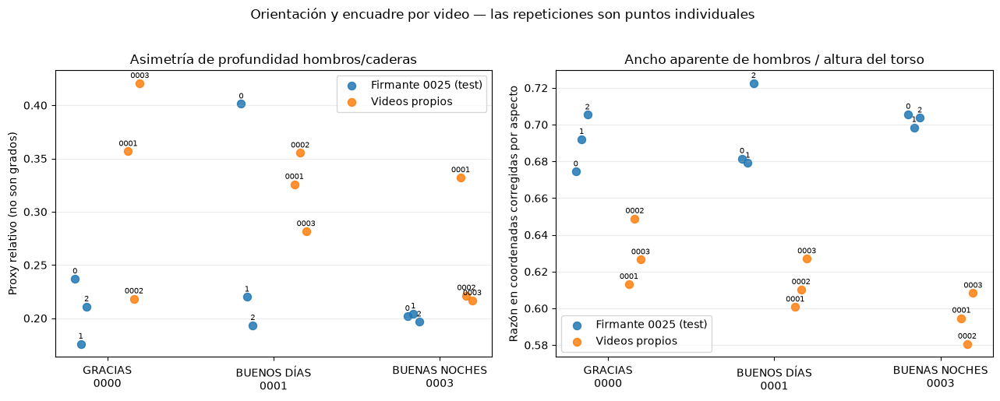

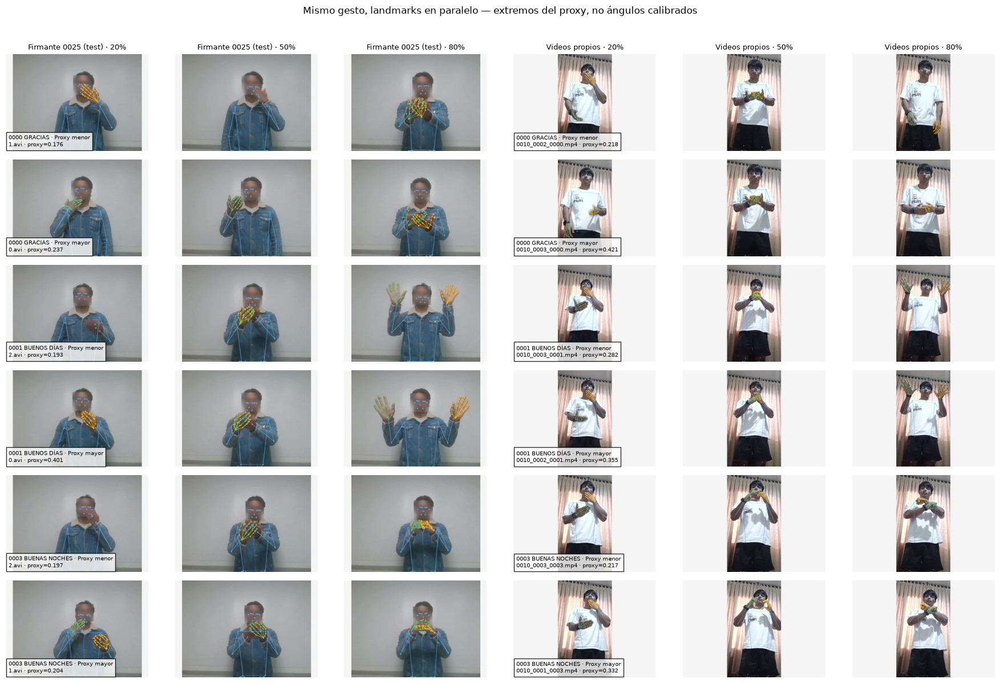

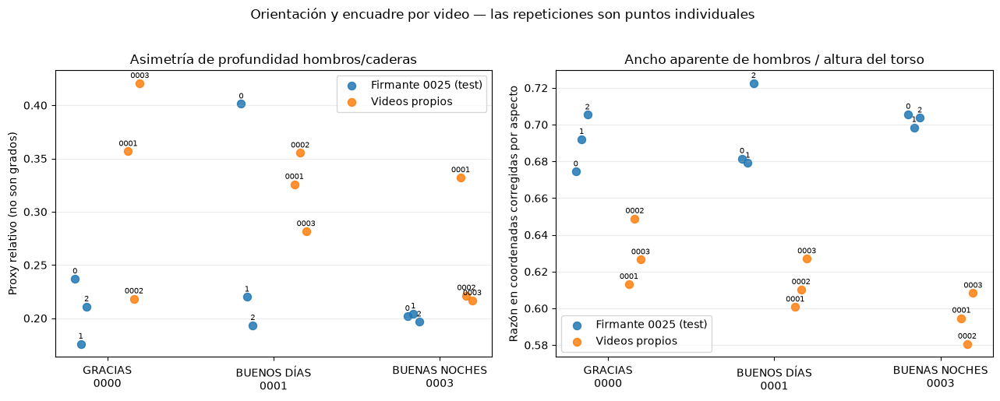

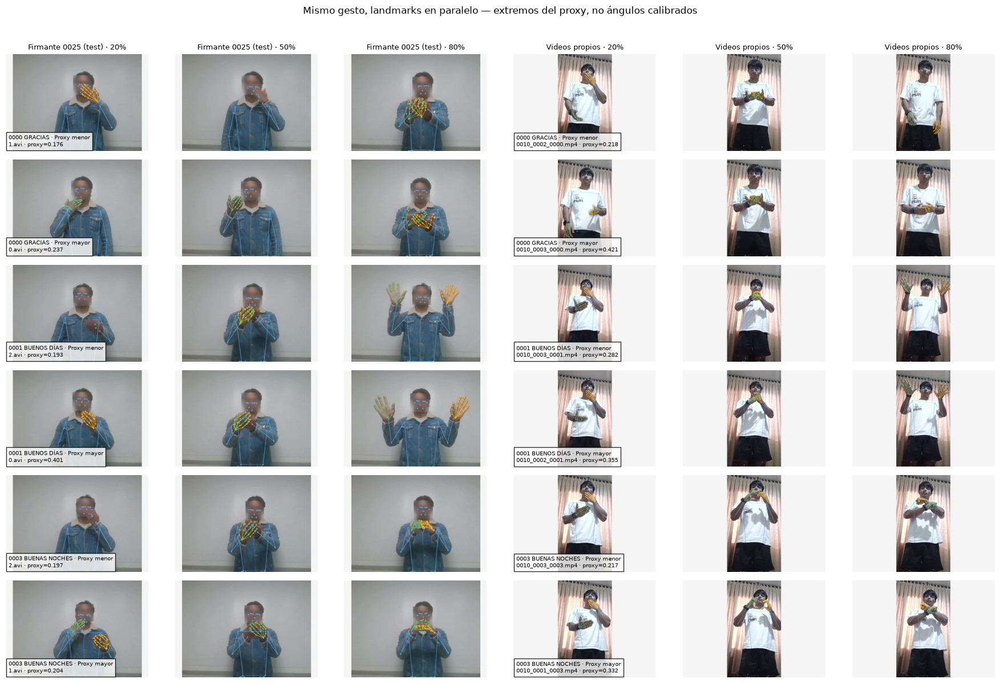

In [27]:
angle_columns = [
    "grupo_nombre", "codigo_real", "sena", "archivo", "proxy_oblicuidad_mediana",
    "proxy_oblicuidad_p75", "ancho_hombros_altura_torso", "inclinacion_hombros_deg",
    "cobertura_pose", "cobertura_mano_izquierda", "cobertura_mano_derecha",
]
display(
    comparison_catalog.sort_values(["grupo", "codigo_real", "proxy_oblicuidad_mediana"])[angle_columns]
    .round(3)
)
display(plot_angle_diagnostics(comparison_catalog, comparison_output_dir))
display(plot_parallel_landmark_examples(comparison_catalog, comparison_output_dir))

### 2. Velocidad temporal y estabilidad de la predicción

Cada secuencia de landmarks se simula a `0.5x`, `1x` y `2x` y luego se remuestrea a los 64 frames del checkpoint. No cambia el FPS de captura ni mide velocidad física absoluta: comprueba si estirar/comprimir uniformemente el gesto cambia la clasificación. Las matrices agrupan las otras 14 clases en `OTRAS`.

,grupo,grupo_nombre,factor_velocidad,aciertos,total,accuracy,probabilidad_real_media,confianza_top1_media,duracion_media_s
0,firmante25,Firmante 0025 (test),0.5,9,9,1.0,0.842,0.842,4.837
1,firmante25,Firmante 0025 (test),1.0,9,9,1.0,0.842,0.842,2.419
2,firmante25,Firmante 0025 (test),2.0,9,9,1.0,0.832,0.832,1.209
3,propio,Videos propios,0.5,0,9,0.0,0.119,0.455,6.028
4,propio,Videos propios,1.0,0,9,0.0,0.119,0.455,3.014
5,propio,Videos propios,2.0,0,9,0.0,0.128,0.470,1.507


,grupo_nombre,archivo,sena_real,prediccion,acierto,confianza_top1,probabilidad_real,top3
1,Firmante 0025 (test),0.avi,GRACIAS,0000,True,0.935,0.935,0000: 93.5% | 0036: 1.8% | 0053: 1.1%
4,Firmante 0025 (test),1.avi,GRACIAS,0000,True,0.599,0.599,0000: 59.9% | 0036: 25.8% | 0002: 4.6%
7,Firmante 0025 (test),2.avi,GRACIAS,0000,True,0.759,0.759,0000: 75.9% | 0053: 5.5% | 0050: 5.3%
10,Firmante 0025 (test),0.avi,BUENOS DÍAS,0001,True,0.792,0.792,0001: 79.2% | 0052: 8.8% | 0053: 2.3%
13,Firmante 0025 (test),1.avi,BUENOS DÍAS,0001,True,0.850,0.850,0001: 85.0% | 0003: 5.2% | 0053: 1.8%
16,Firmante 0025 (test),2.avi,BUENOS DÍAS,0001,True,0.872,0.872,0001: 87.2% | 0050: 2.4% | 0027: 2.0%
19,Firmante 0025 (test),0.avi,BUENAS NOCHES,0003,True,0.911,0.911,0003: 91.1% | 0001: 2.3% | 0035: 1.1%
22,Firmante 0025 (test),1.avi,BUENAS NOCHES,0003,True,0.951,0.951,0003: 95.1% | 0036: 0.8% | 0035: 0.7%
25,Firmante 0025 (test),2.avi,BUENAS NOCHES,0003,True,0.905,0.905,0003: 90.5% | 0052: 2.4% | 0053: 1.7%
28,Videos propios,0010_0001_0000.mp4,GRACIAS,0036,False,0.366,0.141,0036: 36.6% | 0000: 14.1% | 0025: 9.8%


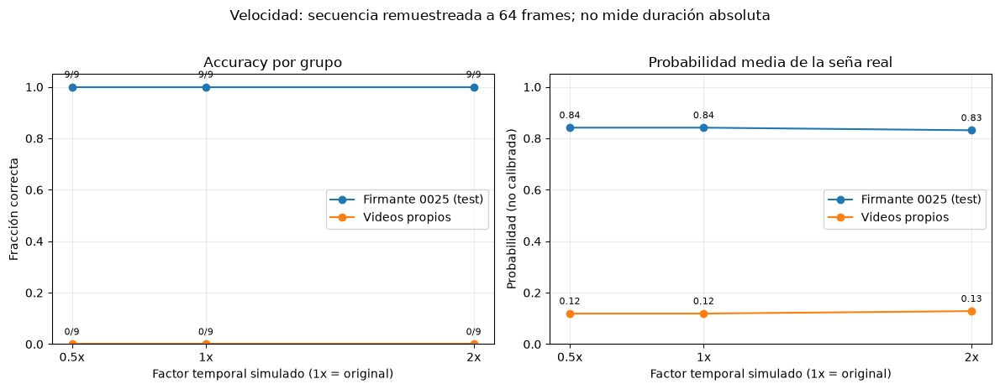

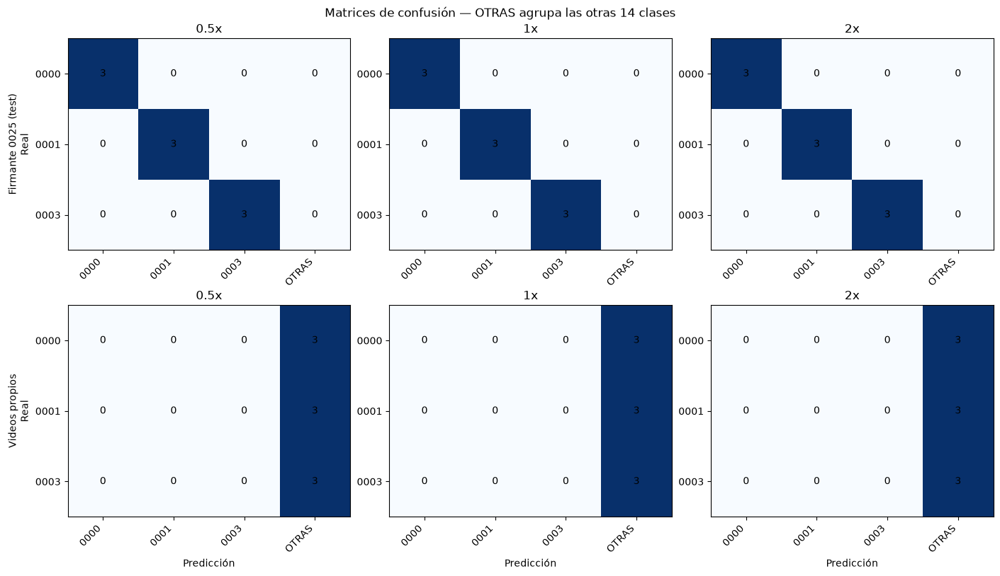

Tablas y figuras guardadas en: D:\Noveno\Fase 2\Reconocimiento-del-Lenguaje-de-Se-as-Colombiano\FASE 2\Codigo\landmark_recognition\data\experimentos_propios\comparacion_firmante_0025_vs_propio


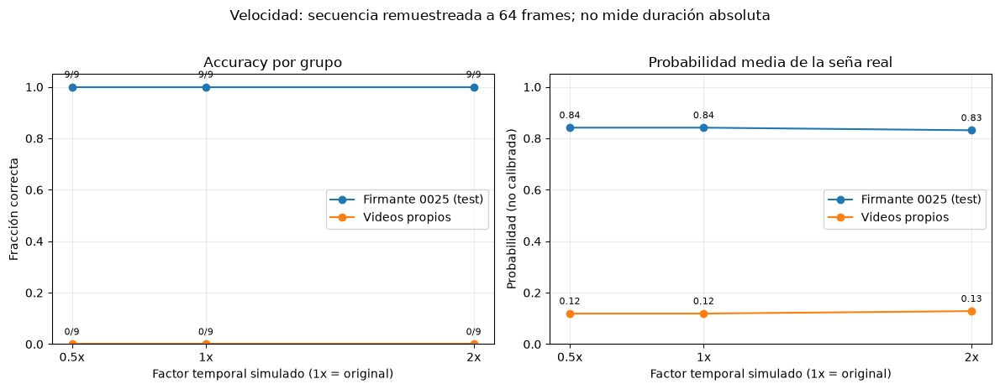

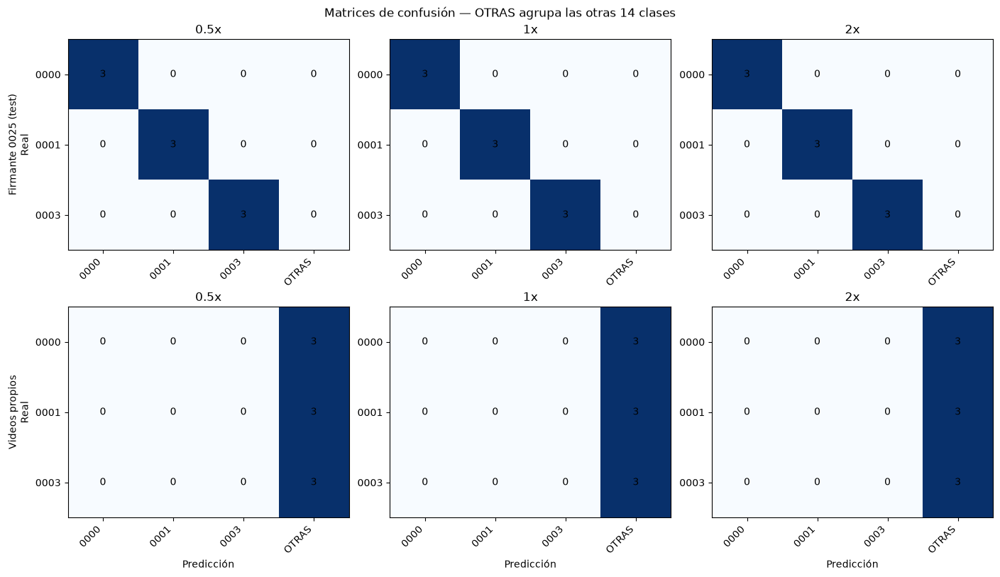

In [28]:
speed_summary = summarize_speed_predictions(comparison_predictions)
display(speed_summary.round(3))
display(
    comparison_predictions.loc[
        comparison_predictions["factor_velocidad"] == 1.0,
        ["grupo_nombre", "archivo", "sena_real", "prediccion", "acierto", "confianza_top1", "probabilidad_real", "top3"],
    ].round(3)
)
display(plot_speed_summary(speed_summary, comparison_output_dir))
display(plot_speed_confusions(comparison_predictions, comparison_output_dir))
print(f"Tablas y figuras guardadas en: {comparison_output_dir}")